# 1. Compreensão do Problema

- Interpretar o contexto do problema.
- Definir claramente a variável alvo.
- Realizar a transformação da variável de qualidade em classificação binária.

## Objetivo

Desenvolver um modelo de classificação capaz de prever a qualidade de um vinho com base em suas características físico-químicas.
Para simplificar o problema, a variável de qualidade deverá ser transformada em uma classificação binária, por exemplo:
- Vinho de Alta Qualidade: nota >= 7
- Vinho de Baixa/Média Qualidade: nota < 7

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import classification_report, make_scorer, f1_score, confusion_matrix
from sklearn.utils import resample
from sklearn.base import clone

from src.pipelines import (pipeline_logistic_regression, pipeline_svc, pipeline_random_forest, pipeline_knn)

In [3]:
SEMENTE = 42

# Nomes das variáveis em português
nomes = {
    'fixed acidity': 'Acidez fixa',
    'volatile acidity': 'Acidez volátil',
    'citric acid': 'Ácido cítrico',
    'residual sugar': 'Açúcar residual',
    'chlorides': 'Cloretos',
    'free sulfur dioxide': 'Dióxido de enxofre livre',
    'total sulfur dioxide': 'Dióxido de enxofre total',
    'density': 'Densidade',
    'pH': 'pH',
    'sulphates': 'Sulfatos',
    'alcohol': 'Teor alcoólico'
}

In [4]:
df_wine = pd.read_csv('../data/WineQT.csv')

In [5]:
df_wine.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


## Variável Alvo

Deverá ser medida a variável 'quality'.

A mesma foi transformada em uma categoria binária ('quality_classification'), onde:
- 0 = vinho de baixa/média qualidade com nota < 7
- 1 = vinho de alta qualidade com nota >= 7

In [6]:
df_wine['quality_classification'] = np.select(
    [
        df_wine['quality'] < 7,
        df_wine['quality'] >= 7
    ],
    [
        0,
        1
    ]
)

df_wine.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id,quality_classification
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4,0


# 2. Análise Exploratória de Dados (EDA)

- Investigar a distribuição das variáveis.
- Identificar correlações entre as variáveis e justificar cada uma delas.
- Detectar possíveis outliers ou valores inconsistentes.
- Analisar o balanceamento das classes

## Análise Inicial

In [7]:
df_wine.shape

(1143, 14)

In [8]:
df_wine.info()

<class 'pandas.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   fixed acidity           1143 non-null   float64
 1   volatile acidity        1143 non-null   float64
 2   citric acid             1143 non-null   float64
 3   residual sugar          1143 non-null   float64
 4   chlorides               1143 non-null   float64
 5   free sulfur dioxide     1143 non-null   float64
 6   total sulfur dioxide    1143 non-null   float64
 7   density                 1143 non-null   float64
 8   pH                      1143 non-null   float64
 9   sulphates               1143 non-null   float64
 10  alcohol                 1143 non-null   float64
 11  quality                 1143 non-null   int64  
 12  Id                      1143 non-null   int64  
 13  quality_classification  1143 non-null   int64  
dtypes: float64(11), int64(3)
memory usage: 125.1 KB


In [9]:
# Verificando o dataset

print("Linhas duplicadas:", df_wine.duplicated().sum())
print()

print("Valores ausentes por coluna:")
print(df_wine.isnull().sum())
print()

print("Valores unicos por coluna:")
print(df_wine.nunique())

Linhas duplicadas: 0

Valores ausentes por coluna:
fixed acidity             0
volatile acidity          0
citric acid               0
residual sugar            0
chlorides                 0
free sulfur dioxide       0
total sulfur dioxide      0
density                   0
pH                        0
sulphates                 0
alcohol                   0
quality                   0
Id                        0
quality_classification    0
dtype: int64

Valores unicos por coluna:
fixed acidity               91
volatile acidity           135
citric acid                 77
residual sugar              80
chlorides                  131
free sulfur dioxide         53
total sulfur dioxide       138
density                    388
pH                          87
sulphates                   89
alcohol                     61
quality                      6
Id                        1143
quality_classification       2
dtype: int64


In [10]:
df_wine.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1143.0,8.311111,1.747595,4.60000,7.10000,7.90000,9.100000,15.90000
volatile acidity,1143.0,0.531339,0.179633,0.12000,0.39250,0.52000,0.640000,1.58000
citric acid,1143.0,0.268364,0.196686,0.00000,0.09000,0.25000,0.420000,1.00000
residual sugar,1143.0,2.532152,1.355917,0.90000,1.90000,2.20000,2.600000,15.50000
chlorides,1143.0,0.086933,0.047267,0.01200,0.07000,0.07900,0.090000,0.61100
free sulfur dioxide,1143.0,15.615486,10.250486,1.00000,7.00000,13.00000,21.000000,68.00000
total sulfur dioxide,1143.0,45.914698,32.782130,6.00000,21.00000,37.00000,61.000000,289.00000
density,1143.0,0.996730,0.001925,0.99007,0.99557,0.99668,0.997845,1.00369
pH,1143.0,3.311015,0.156664,2.74000,3.20500,3.31000,3.400000,4.01000
sulphates,1143.0,0.657708,0.170399,0.33000,0.55000,0.62000,0.730000,2.00000


In [11]:
print("Contagem quality_classification:")
print(df_wine['quality_classification'].value_counts())
print()

print("Percentual quality_classification:")
print(df_wine['quality_classification'].value_counts(normalize=True) * 100)

Contagem quality_classification:
quality_classification
0    984
1    159
Name: count, dtype: int64

Percentual quality_classification:
quality_classification
0    86.089239
1    13.910761
Name: proportion, dtype: float64


Desbalanceamento entre as classes. Há muito mais vinhos de média/baixa qualidade, do que vinhos de alta qualidade.

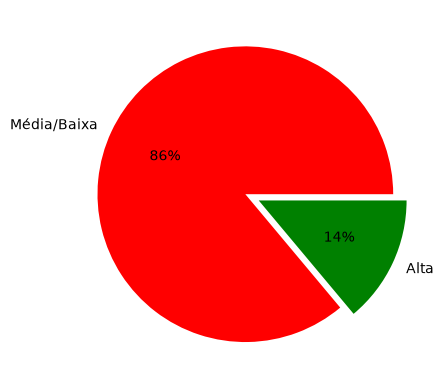

In [12]:
categorias = ['Média/Baixa', 'Alta']
plt.pie(df_wine['quality_classification'].value_counts(), labels=categorias, autopct='%.0f%%', explode=(0, 0.1), colors=('r', 'g'))
plt.show()

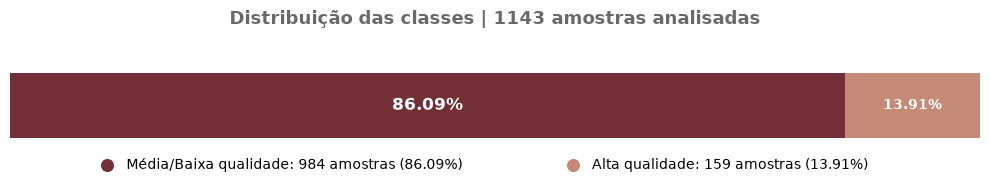

In [13]:
# Gráfico para o relatório executivo

# Contagem e percentual de cada classe
contagem = df_wine['quality_classification'].value_counts().reindex([0, 1], fill_value=0)
percentual = contagem / contagem.sum() * 100

# Cores das classes (cores que remetam a vinho)
cor_classe_0 = '#722F37'  # Bordô
cor_classe_1 = '#C58A78'  # Rosé queimado

# Criando o gráfico
fig, ax = plt.subplots(figsize=(10, 2))

# Barra horizontal empilhada
ax.barh(0, percentual[0],                     color=cor_classe_0, height=0.35)
ax.barh(0, percentual[1], left=percentual[0], color=cor_classe_1, height=0.35)

# Percentuais dentro das barras
ax.text(
    percentual[0] / 2, 0,
    f'{percentual[0]:.2f}%',
    ha='center', va='center', color='white', fontsize=12, fontweight='bold'
)

ax.text(
    percentual[0] + percentual[1] / 2, 0,
    f'{percentual[1]:.2f}%',
    ha='center', va='center', color='white', fontsize=10, fontweight='bold'
)

# Título
ax.set_title(
    f'Distribuição das classes | {contagem.sum():} amostras analisadas',
    loc='center', color='#696969', fontsize=13, fontweight='bold', pad=5
)

# Removendo elementos dos eixos
ax.set_xlim(0, 100)
ax.set_ylim(-0.4, 0.4)
ax.axis('off')

# Legenda manual
ax.scatter(10, -0.32, color=cor_classe_0, s=70, clip_on=False)
ax.text(
    12, -0.32,
    f'Média/Baixa qualidade: {contagem[0]} amostras ({percentual[0]:.2f}%)',
    va='center', fontsize=10
)

ax.scatter(58, -0.32, color=cor_classe_1, s=70, clip_on=False)
ax.text(
    60, -0.32,
    f'Alta qualidade: {contagem[1]} amostras ({percentual[1]:.2f}%)',
    va='center', fontsize=10
)

plt.tight_layout()
plt.show()

## Entendendo como as variáveis estão distribuídas

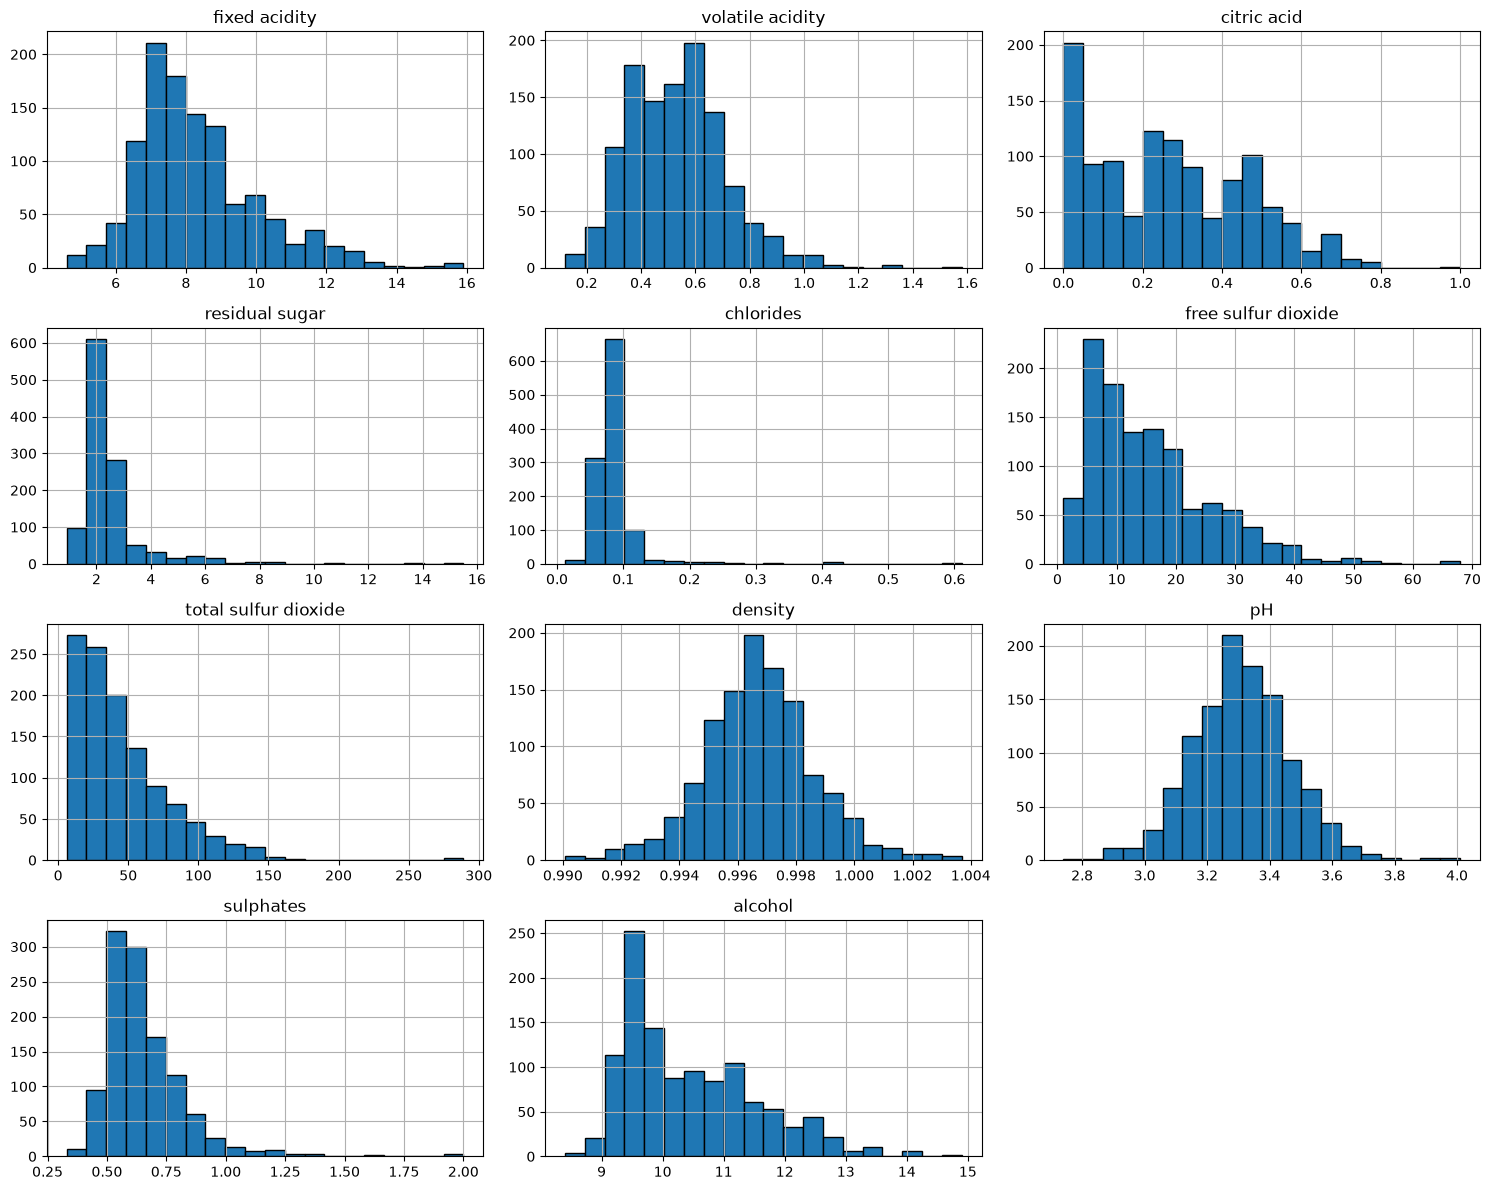

In [14]:
features = df_wine.drop(columns=['Id', 'quality', 'quality_classification'])

features.hist(figsize=(15, 12), bins=20, edgecolor='black')

plt.tight_layout()
plt.show()

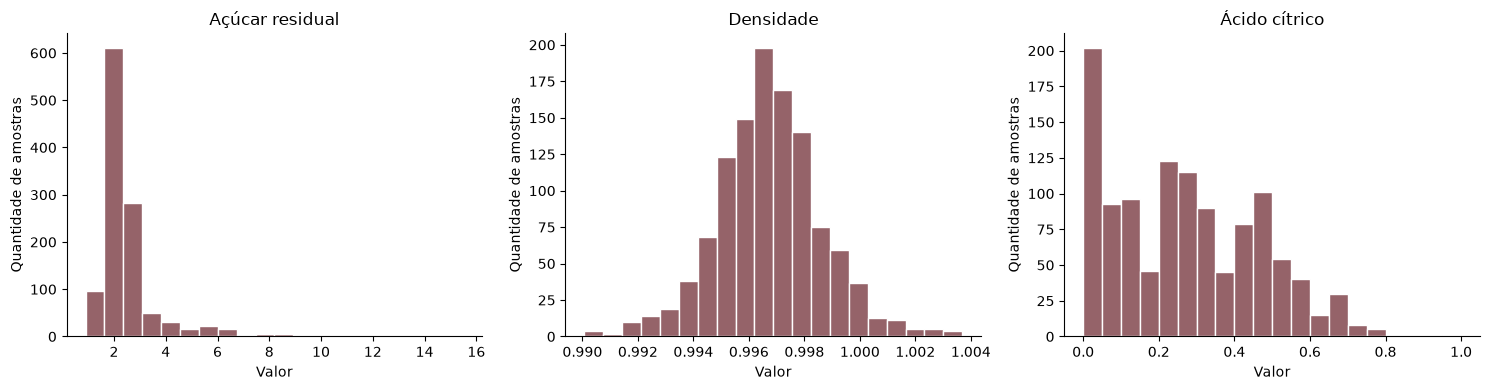

In [15]:
# Gráfico para o relatório executivo

cor = '#722F37'

# Variáveis selecionadas
variaveis = ['residual sugar', 'density', 'citric acid']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, variavel in enumerate(variaveis):
    sns.histplot(data=df_wine, x=variavel, bins=20, color=cor, edgecolor='white', ax=axes[i])

    axes[i].set_title(nomes[variavel], fontsize=12)    
    axes[i].set_xlabel('Valor')
    axes[i].set_ylabel('Quantidade de amostras')

sns.despine()
plt.tight_layout()
plt.show()

## Entendendo os outliers

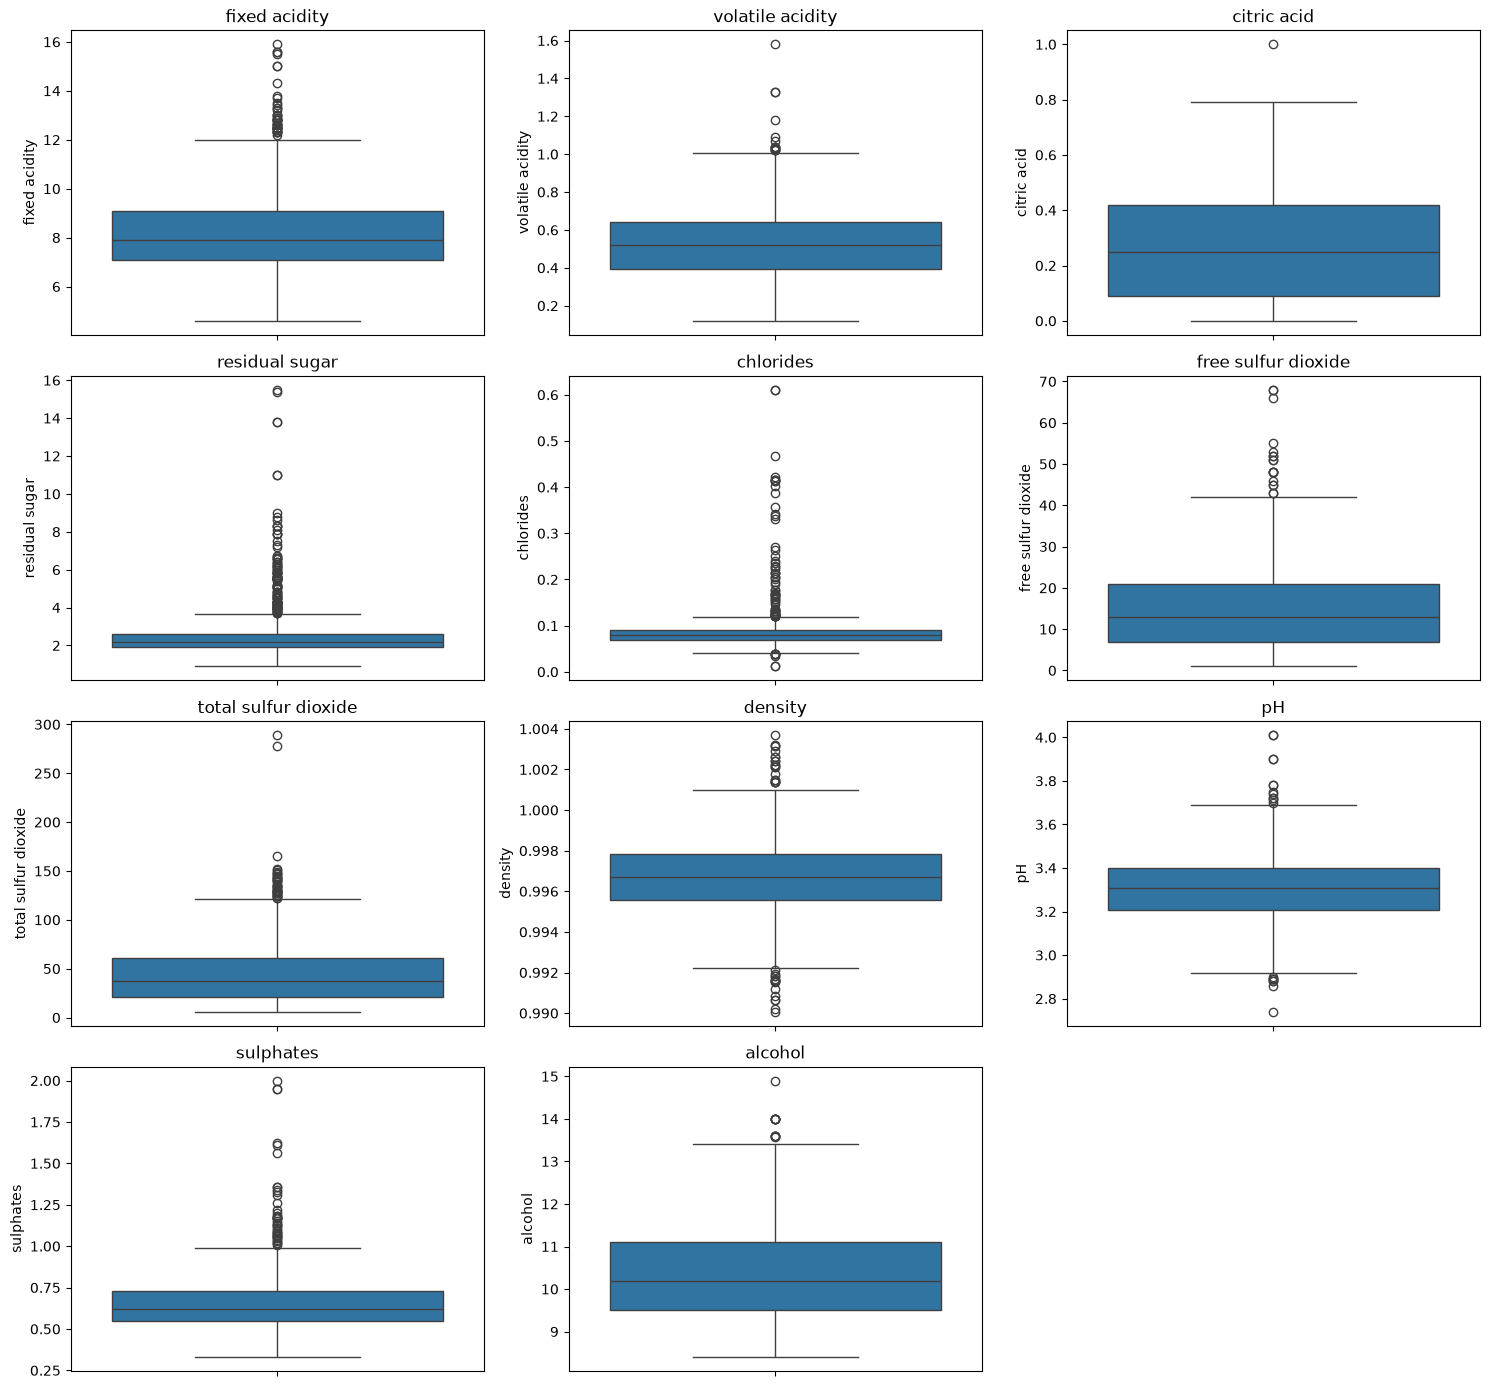

In [16]:
fig, axes = plt.subplots(4, 3, figsize=(15, 14))

for ax, column in zip(axes.flatten(), features.columns):
    sns.boxplot(data=df_wine, y=column, ax=ax)
    ax.set_title(column)

# Remove o último gráfico vazio
axes.flatten()[-1].axis('off')

plt.tight_layout()
plt.show()

Muitos outliers deverão ser mantidos nesta etapa, e seu impacto será avaliado posteriormente durante o treinamento e a avaliação dos modelos.

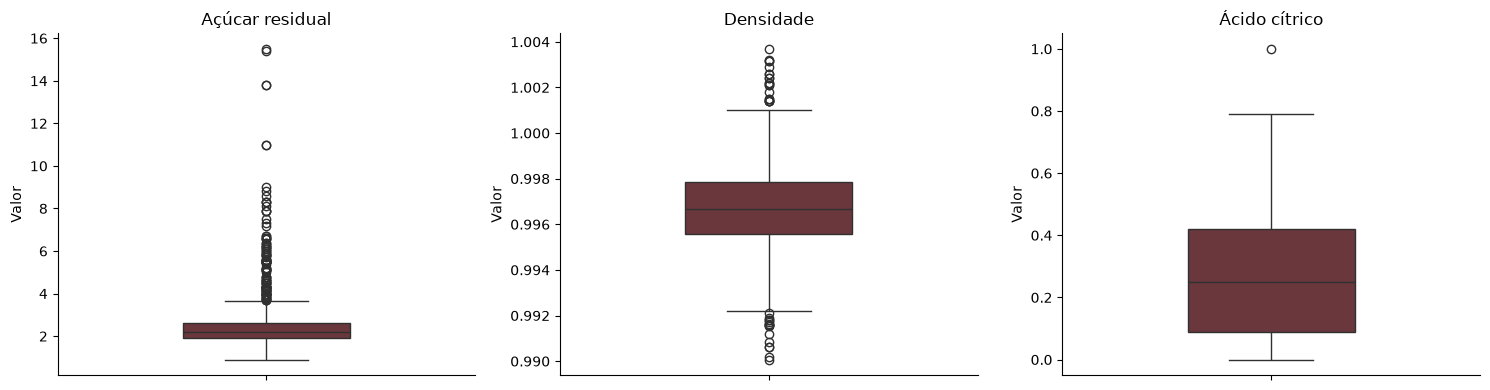

In [17]:
# Gráfico para o relatório executivo

cor = '#722F37'

# Variáveis selecionadas
variaveis = ['residual sugar', 'density', 'citric acid']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, variavel in enumerate(variaveis):
    sns.boxplot(data=df_wine, y=variavel, color=cor, width=0.4, ax=axes[i])

    axes[i].set_title(nomes[variavel], fontsize=12)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Valor')

sns.despine()
plt.tight_layout()
plt.show()

## Entendendo a correlação entre as variáveis

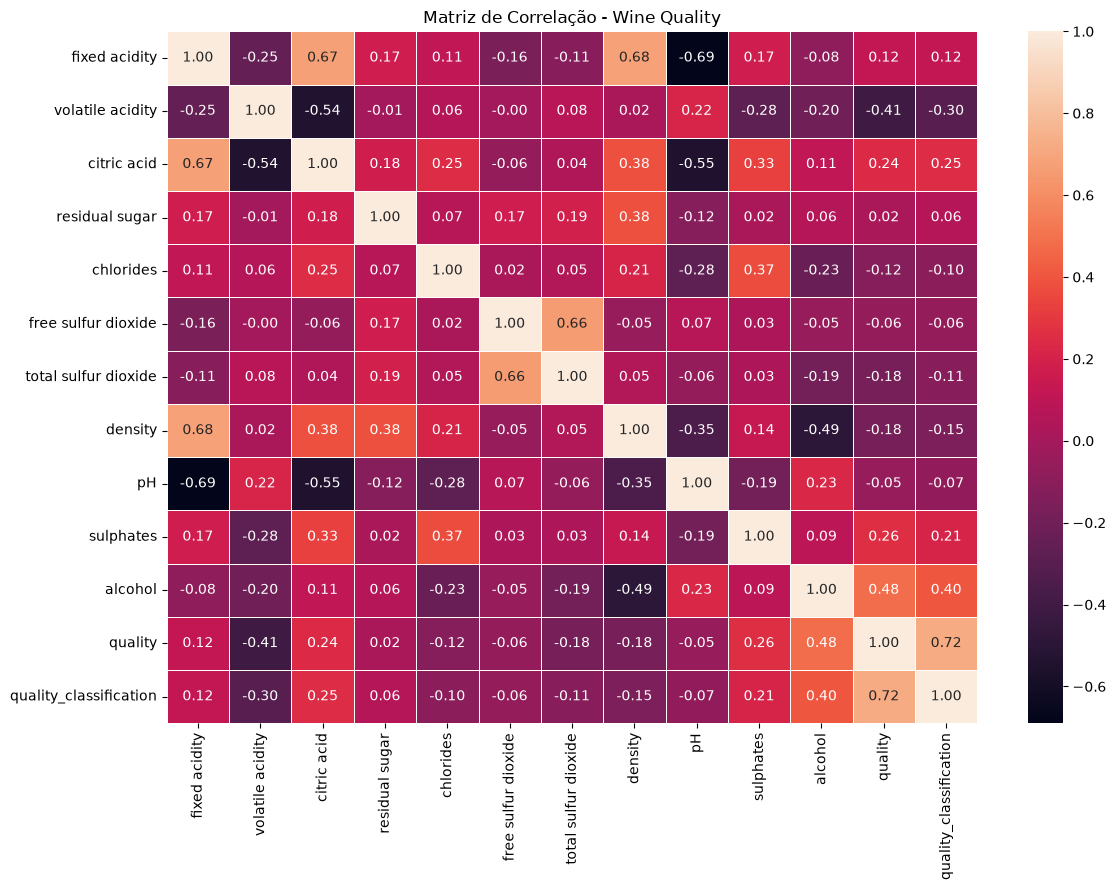

In [18]:
correlation = df_wine.drop(columns=['Id']).corr().round(2) # removendo a coluna ID da análise, porque ela é um valor único

plt.figure(figsize=(12,9))    
sns.heatmap(data=correlation, annot=True, linewidths=0.5, fmt='.2f')

plt.title('Matriz de Correlação - Wine Quality')
plt.tight_layout()
plt.show()

Acidez Volátil (volatile acidity), Acidez Cítrica (citric acid), Sulfatos (sulphates) e Teor Alcoólico (alcohol) apresentaram maior associação com a qualidade do vinho.

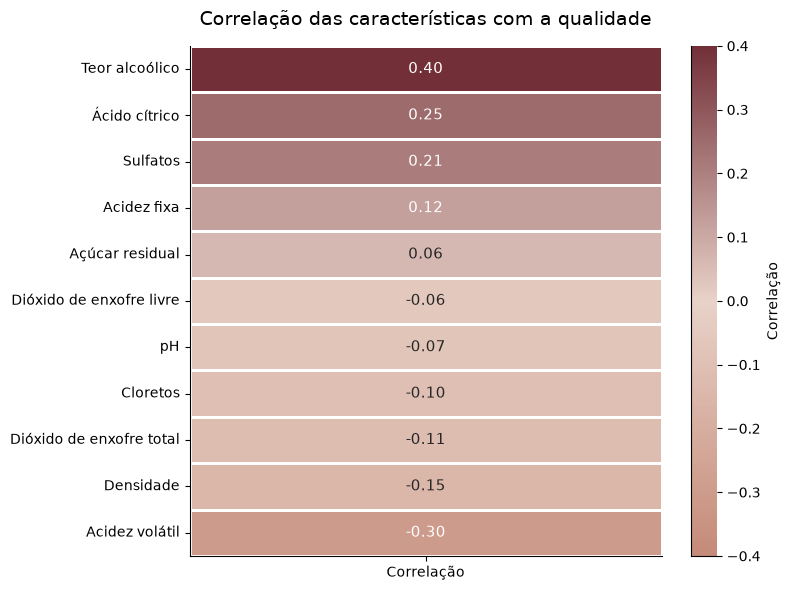

In [19]:
# Gráfico para o relatório executivo

correlacoes = (df_wine.corr(numeric_only=True)['quality_classification'].drop(['quality_classification', 'quality', 'Id'], errors='ignore'))

# Ordenando do maior para o menor
correlacoes = correlacoes.sort_values(ascending=False)

cores = [
    '#722F37' if valor >= 0 else '#C58A78'
    for valor in correlacoes
]

nomes_pt = [nomes.get(nome, nome) for nome in correlacoes.index]

# Preparar os dados
dados_grafico = correlacoes.to_frame(name='Correlação')
dados_grafico.index = nomes_pt

# Criar paleta personalizada com Seaborn
paleta_vinho = sns.blend_palette(
    #['#C58A78', '#F3E9E2', '#722F37'],
    #['#A96767', '#E8D2C8', '#722F37'],
    ['#C58A78', '#E8D2C8', '#722F37'],
    as_cmap=True
)

plt.figure(figsize=(8, 6))

ax = sns.heatmap(
    dados_grafico, annot=True, fmt='.2f', cmap=paleta_vinho,
    center=0, vmin=-0.4, vmax=0.4, linewidths=1, linecolor='white', cbar_kws={'label': 'Correlação'}, annot_kws={'fontsize': 11}
)

ax.set_title('Correlação das características com a qualidade', fontsize=14, pad=15)
ax.set_xlabel('')
ax.set_ylabel('')

sns.despine()
plt.tight_layout()
plt.show()

# 3. Pré-processamento de Dados

- Tratamento de dados faltantes (se houver).
- Normalização ou padronização de variáveis numéricas.
- Criação de novas features (feature engineering), se considerado relevante.

## Separação da base de treino e teste

In [20]:
# Separação das variáveis preditoras e variável alvo

x = df_wine.drop(columns=['Id', 'quality', 'quality_classification'])
y = df_wine['quality_classification'] # variável alvo (target)

In [21]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, stratify=y, random_state=SEMENTE) #20% para teste e 80% de treino

In [22]:
print(f'Treino: {x_train.shape}')
print(f'Teste: {x_test.shape}')

print('\nDistribuição das classes - Treino:')
print(y_train.value_counts(normalize=True) * 100)

print('\nDistribuição das classes - Teste:')
print(y_test.value_counts(normalize=True) * 100)

Treino: (914, 11)
Teste: (229, 11)

Distribuição das classes - Treino:
quality_classification
0    86.105033
1    13.894967
Name: proportion, dtype: float64

Distribuição das classes - Teste:
quality_classification
0    86.026201
1    13.973799
Name: proportion, dtype: float64


## Feature Scaling

A padronização da escala dos dados será feita dentro do pipeline (./src/pipelines.py), afim de evitar duplicidade de processamento e vazamento de dados.

# 4. Desenvolvimento de Modelos

Treinar pelo menos dois modelos de classificação, e comparar o desempenho entre eles.

## Definição dos modelos

Para realizar a classificação, foram escolhidos quatro modelos diferentes:

- **Regressão Logística:** utilizada como uma abordagem inicial para classificar os vinhos.
- **SVC (Support Vector Classifier):** busca encontrar a melhor separação entre as classes.
- **Random Forest:** combina várias árvores de decisão para realizar a classificação.
- **KNN (K-Nearest Neighbors):** classifica os vinhos considerando os exemplos mais semelhantes.

A escolha desses modelos permite comparar diferentes formas de classificação e identificar qual apresenta os melhores resultados para o problema.

## Treinando os modelos (sem oversampling)

In [23]:
# Regressão Logística
pipeline_logistic_regression.fit(x_train, y_train)

# SVC
pipeline_svc.fit(x_train, y_train)

# Random Forest
pipeline_random_forest.fit(x_train, y_train)

# KNN
pipeline_knn.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['fixed acidity','volatile acidity','citric acid',...,'pH','sulphates', 'alcohol']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [24]:
y_pred_logistic_regression = pipeline_logistic_regression.predict(x_test)

y_pred_svc = pipeline_svc.predict(x_test)

y_pred_random_forest = pipeline_random_forest.predict(x_test)

y_pred_knn = pipeline_knn.predict(x_test)

In [25]:
# Conferindo se todos os modelos avaliaram a mesma quantidade de registros

print('Regressão Logística:', len(y_pred_logistic_regression))
print('SVC:', len(y_pred_svc))
print('Random Forest:', len(y_pred_random_forest))
print('KNN:', len(y_pred_knn))
print('Valores reais:', len(y_test))

Regressão Logística: 229
SVC: 229
Random Forest: 229
KNN: 229
Valores reais: 229


### Resultados dos modelos (sem oversampling)

In [26]:
print('Regressão Logística')
print(classification_report(y_test, y_pred_logistic_regression))

print('SVC')
print(classification_report(y_test, y_pred_svc))

print('Random Forest')
print(classification_report(y_test, y_pred_random_forest))

print('KNN')
print(classification_report(y_test, y_pred_knn))

Regressão Logística
              precision    recall  f1-score   support

           0       0.94      0.82      0.88       197
           1       0.38      0.69      0.49        32

    accuracy                           0.80       229
   macro avg       0.66      0.75      0.68       229
weighted avg       0.86      0.80      0.82       229

SVC
              precision    recall  f1-score   support

           0       0.95      0.83      0.89       197
           1       0.41      0.72      0.52        32

    accuracy                           0.82       229
   macro avg       0.68      0.78      0.70       229
weighted avg       0.87      0.82      0.84       229

Random Forest
              precision    recall  f1-score   support

           0       0.94      0.93      0.94       197
           1       0.60      0.66      0.63        32

    accuracy                           0.89       229
   macro avg       0.77      0.79      0.78       229
weighted avg       0.90      0.89   

## Otimização do Random Forest (GridSearchCV)

O Random Forest apresentou o melhor desempenho entre os quatro modelos avaliados, considerando o Macro F1-score.

Por isso, foi escolhido para um novo experimento, utilizando o GridSearchCV para buscar uma combinação de hiperparâmetros que pudesse melhorar seus resultados.

In [27]:
# Busca de hiperparâmetros que maximizam o f1-score

param_grid = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [None, 5, 10, 15],
    'model__min_samples_split': [2, 5, 10]
}

scorer = make_scorer(f1_score, average='macro')

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)

grid = GridSearchCV(estimator=pipeline_random_forest,
                    param_grid=param_grid,
                    scoring=scorer,
                    cv=cv, n_jobs=-1)

grid.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [None, 5, ...], 'model__min_samples_split': [2, 5, ...], 'model__n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",make_scorer(f...average=macro)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:

In [28]:
print('Melhores parâmetros:', grid.best_params_)
print('Melhor Macro F1:', grid.best_score_)

Melhores parâmetros: {'model__max_depth': None, 'model__min_samples_split': 2, 'model__n_estimators': 300}
Melhor Macro F1: 0.7777270322107016


In [29]:
best_model = grid.best_estimator_

y_pred_rf_tuned = best_model.predict(x_test)

print(classification_report(y_test, y_pred_rf_tuned))

              precision    recall  f1-score   support

           0       0.94      0.92      0.93       197
           1       0.57      0.62      0.60        32

    accuracy                           0.88       229
   macro avg       0.75      0.77      0.76       229
weighted avg       0.89      0.88      0.88       229



Apesar da busca por melhores hiperparâmetros, o Random Forest otimizado apresentou desempenho inferior ao modelo original no conjunto de teste.

O Macro F1 passou de 0.78 para 0.76, indicando que a otimização não trouxe ganho de desempenho neste experimento.

## Balanceamento dos dados (Oversampling)

Como a base apresenta uma quantidade menor de vinhos classificados como alta qualidade, foi aplicado o oversampling para aumentar a representatividade dessa classe no conjunto de treinamento.

O conjunto de teste foi mantido sem alterações, preservando a distribuição original dos dados para a avaliação dos modelos.

In [30]:
# Preservando o conjunto de teste original, sem balancear

x_train_0 = x_train[y_train == 0]
x_train_1 = x_train[y_train == 1]

y_train_0 = y_train[y_train == 0]
y_train_1 = y_train[y_train == 1]

print('Classe 0:', len(x_train_0))
print('Classe 1:', len(x_train_1))

Classe 0: 787
Classe 1: 127


In [31]:
# Aplicando oversampling
x_train_1_resampled, y_train_1_resampled = resample(x_train_1, y_train_1, replace=True, n_samples=len(x_train_0), random_state=SEMENTE)

In [32]:
# Juntando os dados
x_train_balanced = pd.concat([x_train_0, x_train_1_resampled])
y_train_balanced = pd.concat([y_train_0, y_train_1_resampled])

In [33]:
print(y_train_balanced.value_counts())

quality_classification
0    787
1    787
Name: count, dtype: int64


## Treinando os modelos (com oversampling)

In [34]:
# Regressão Logística
pipeline_logistic_regression.fit(x_train_balanced, y_train_balanced)

# SVC
pipeline_svc.fit(x_train_balanced, y_train_balanced)

# Random Forest
pipeline_random_forest.fit(x_train_balanced, y_train_balanced)

# KNN
pipeline_knn.fit(x_train_balanced, y_train_balanced)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['fixed acidity','volatile acidity','citric acid',...,'pH','sulphates', 'alcohol']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [35]:
y_pred_logistic_regression_balanced = pipeline_logistic_regression.predict(x_test)

y_pred_svc_balanced = pipeline_svc.predict(x_test)

y_pred_random_forest_balanced = pipeline_random_forest.predict(x_test)

y_pred_knn_balanced = pipeline_knn.predict(x_test)

In [36]:
# Conferindo se todos os modelos avaliaram a mesma quantidade de registros

print('Regressão Logística:', len(y_pred_logistic_regression_balanced))
print('SVC:', len(y_pred_svc_balanced))
print('Random Forest:', len(y_pred_random_forest_balanced))
print('KNN:', len(y_pred_knn_balanced))
print('Valores reais:', len(y_test))

Regressão Logística: 229
SVC: 229
Random Forest: 229
KNN: 229
Valores reais: 229


### Resultados dos modelos (com oversampling)

In [37]:
print('Regressão Logística')
print(classification_report(y_test, y_pred_logistic_regression_balanced))

print('SVC')
print(classification_report(y_test, y_pred_svc_balanced))

print('Random Forest')
print(classification_report(y_test, y_pred_random_forest_balanced))

print('KNN')
print(classification_report(y_test, y_pred_knn_balanced))

Regressão Logística
              precision    recall  f1-score   support

           0       0.94      0.82      0.88       197
           1       0.39      0.69      0.49        32

    accuracy                           0.80       229
   macro avg       0.66      0.75      0.69       229
weighted avg       0.86      0.80      0.82       229

SVC
              precision    recall  f1-score   support

           0       0.95      0.83      0.89       197
           1       0.41      0.72      0.52        32

    accuracy                           0.82       229
   macro avg       0.68      0.78      0.70       229
weighted avg       0.87      0.82      0.84       229

Random Forest
              precision    recall  f1-score   support

           0       0.94      0.96      0.95       197
           1       0.70      0.59      0.64        32

    accuracy                           0.91       229
   macro avg       0.82      0.78      0.80       229
weighted avg       0.90      0.91   

Após a aplicação do oversampling, o Random Forest continuou apresentando o melhor desempenho entre os modelos avaliados.

O Macro F1 passou de 0.78 para 0.80, indicando uma pequena melhora no equilíbrio entre as classes. Já o F1-score da classe de alta qualidade passou de 0.63 para 0.64.

A acurácia também apresentou aumento, passando de 0.89 para 0.91.

Esses resultados indicam que o oversampling trouxe uma melhora discreta para o Random Forest, embora o ganho tenha sido limitado.

# 5. Avaliação dos Modelos

Avaliar os modelos utilizando métricas adequadas. Também deve ser realizada uma comparação entre os modelos testados.

## Métricas de avaliação

Para avaliar os modelos, foram utilizadas as seguintes métricas:

- **Acurácia (Accuracy):** mostra a porcentagem de acertos do modelo.
- **Precisão (Precision):** mostra quantas das previsões de uma classe estavam corretas.
- **Revocação (Recall):** mostra quantos registros de uma classe o modelo conseguiu identificar.
- **F1-score:** considera a precisão e a revocação em conjunto.
- **Macro F1-score:** calcula a média do F1-score das duas classes, considerando ambas com o mesmo peso.

Como a base possui mais registros de vinhos de média/baixa qualidade do que de alta qualidade, o **Macro F1-score será a principal métrica** utilizada na comparação dos modelos.

## Comparação dos modelos

**Modelos sem oversampling**

| Modelo | Macro F1 | F1 classe 1 (Alta) | F1 classe 0 (Média/Baixa) | Acurácia |
|---|---:|---:|---:|---:|
| Regressão Logística | 0.68 | 0.49 | 0.88 | 0.80 |
| SVC | 0.70 | 0.52 | 0.89 | 0.82 |
| **Random Forest** | **0.78** | **0.63** | **0.94** | **0.89** |
| KNN | 0.70 | 0.47 | 0.92 | 0.86 |

**Modelos com oversampling**

| Modelo | Macro F1 | F1 classe 1 (Alta) | F1 classe 0 (Média/Baixa) | Acurácia |
|---|---:|---:|---:|---:|
| Regressão Logística | 0.69 | 0.49 | 0.88 | 0.80 |
| SVC | 0.70 | 0.52 | 0.89 | 0.82 |
| **Random Forest** | **0.80** | **0.64** | **0.95** | **0.91** |
| KNN | 0.70 | 0.52 | 0.87 | 0.80 |

Ao comparar os resultados, o Random Forest apresentou o melhor desempenho geral, tanto sem quanto com oversampling.

A aplicação do oversampling trouxe uma pequena melhora para esse modelo, com aumento do Macro F1 de 0.78 para 0.80 e do F1 da classe de alta qualidade de 0.63 para 0.64.

Nos demais modelos, os resultados permaneceram praticamente iguais. No KNN, houve melhora na identificação dos vinhos de alta qualidade, mas a acurácia diminuiu.

De forma geral, o Random Forest apresentou os resultados mais consistentes entre os modelos avaliados.

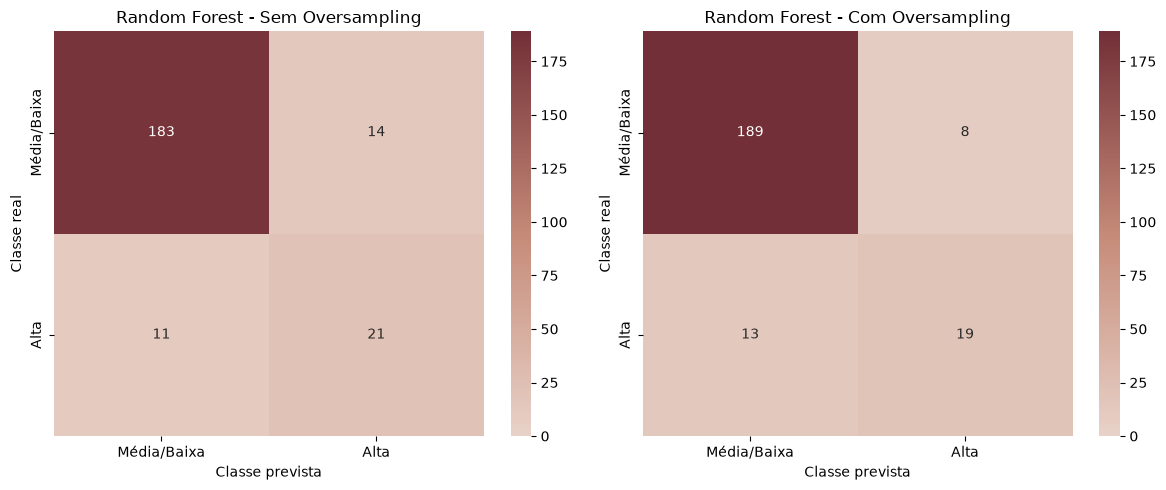

In [38]:
# Calculando as matrizes de confusão
cm_rf = confusion_matrix(y_test, y_pred_random_forest)
cm_rf_balanced = confusion_matrix(y_test, y_pred_random_forest_balanced)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Criar paleta personalizada com Seaborn
paleta_vinho = sns.blend_palette(
    ['#E8D2C8', '#C58A78', '#722F37'],
    as_cmap=True
)

# Random Forest sem oversampling
sns.heatmap(
    cm_rf, annot=True, fmt='d', cmap=paleta_vinho, 
    xticklabels=['Média/Baixa', 'Alta'], yticklabels=['Média/Baixa', 'Alta'], ax=axes[0],
    vmin=0, vmax=max(cm_rf.max(), cm_rf_balanced.max())
)
axes[0].set_title('Random Forest - Sem Oversampling')
axes[0].set_xlabel('Classe prevista')
axes[0].set_ylabel('Classe real')

# Random Forest com oversampling
sns.heatmap(
    cm_rf_balanced, annot=True, fmt='d', cmap=paleta_vinho,
    xticklabels=['Média/Baixa', 'Alta'], yticklabels=['Média/Baixa', 'Alta'], ax=axes[1],
    vmin=0, vmax=max(cm_rf.max(), cm_rf_balanced.max())
)
axes[1].set_title('Random Forest - Com Oversampling')
axes[1].set_xlabel('Classe prevista')
axes[1].set_ylabel('Classe real')

plt.tight_layout()
plt.show()

## Análise do impacto do oversampling

A aplicação do oversampling apresentou resultados diferentes entre os modelos avaliados.

O Random Forest teve uma pequena melhora, com aumento do Macro F1 de 0.78 para 0.80.

O KNN também apresentou melhora no F1 da classe de alta qualidade, passando de 0.47 para 0.52, mas teve uma redução na acurácia.

Já a Regressão Logística e o SVC apresentaram resultados praticamente iguais nas duas condições.

De forma geral, o oversampling trouxe benefícios limitados, com maior destaque para o Random Forest.

***Observação metodológica:** nos dois experimentos, foi utilizado o parâmetro class_weight='balanced' nos modelos que oferecem esse recurso.*

*Portanto, a comparação considera o impacto adicional do oversampling, mantendo a ponderação das classes nas duas configurações.*

## Comparação do Random Forest com 11 e 4 variáveis

Como o Random Forest foi o modelo que melhor performou, é possível utilizar o atributo feature_importances_ para avaliar o peso de cada variável nas decisões das árvores.

In [39]:
feature_importance = pd.DataFrame({
    'feature': x_train.columns,
    'importance': pipeline_random_forest.named_steps['model'].feature_importances_
})

feature_importance = feature_importance.sort_values(by='importance', ascending=False)

feature_importance

,feature,importance
10,alcohol,0.215842
9,sulphates,0.157088
2,citric acid,0.114697
1,volatile acidity,0.107358
7,density,0.079290
0,fixed acidity,0.068064
6,total sulfur dioxide,0.065451
8,pH,0.053004
4,chlorides,0.051323
3,residual sugar,0.045415


In [40]:
selected_features = ['alcohol', 'sulphates', 'citric acid', 'volatile acidity']

x_train_selected = x_train[selected_features]
x_test_selected = x_test[selected_features]

In [41]:
pipeline_rf_selected = clone(pipeline_random_forest)

pipeline_rf_selected.fit(x_train_selected, y_train)

y_pred_rf_selected = pipeline_rf_selected.predict(x_test_selected)

In [42]:
print(classification_report(y_test, y_pred_rf_selected))

              precision    recall  f1-score   support

           0       0.94      0.92      0.93       197
           1       0.57      0.66      0.61        32

    accuracy                           0.88       229
   macro avg       0.76      0.79      0.77       229
weighted avg       0.89      0.88      0.89       229



Embora quatro variáveis tenham concentrado aproximadamente 59.5% da importância total no Random Forest, a utilização de todas as 11 variáveis preditoras apresentou melhor desempenho.

Isso sugere que características de menor importância individual também podem contribuir para a capacidade de classificação quando consideradas em conjunto.

***Observação metodológica:** a importância das variáveis foi extraída do Random Forest treinado com oversampling.*

*Já o experimento de avaliação com as quatro variáveis selecionadas foi treinado sem oversampling, assim como o modelo de referência com as 11 variáveis.*
*Dessa forma, a comparação de desempenho mantém a mesma condição de treinamento, embora a seleção das variáveis tenha sido orientada pelo modelo treinado com oversampling.*

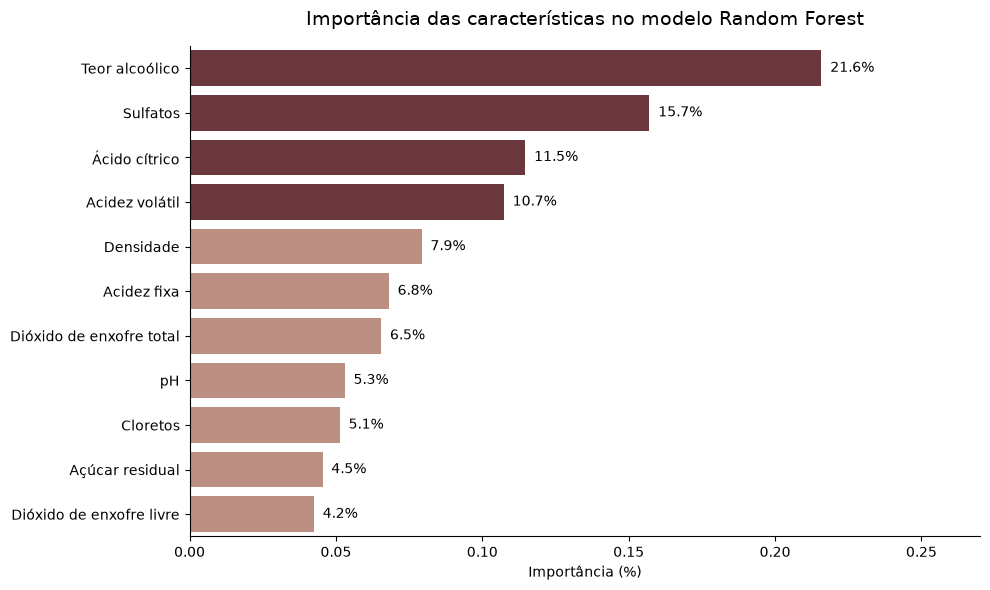

In [43]:
# Gráfico para o relatório executivo

feature_importance['feature_pt'] = feature_importance['feature'].map(nomes)

# Destacar as quatro características mais importantes
feature_importance['cor'] = [
    '#722F37' if valor >= 0.107358 else '#C58A78'
    for valor in feature_importance['importance']
]

# Criar gráfico
fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=feature_importance, x='importance', y='feature_pt', hue='feature_pt',
    palette=feature_importance.set_index('feature_pt')['cor'].to_dict(),
    legend=False, ax=ax
)

# Valores percentuais
for i, valor in enumerate(feature_importance['importance']):
    ax.text(
        valor + 0.003, i,
        f'{valor * 100:.1f}%',
        va='center', fontsize=10
    )

ax.set_title('Importância das características no modelo Random Forest', fontsize=14, pad=15)

ax.set_xlabel('Importância (%)')
ax.set_ylabel('')
ax.set_xlim(0, 0.27)

sns.despine()
plt.tight_layout()
plt.show()

# 6. Interpretação dos Resultados

- Identificar quais variáveis parecem ter maior influência na qualidade do vinho.
- Discutir possíveis implicações para o processo de produção.

## Variáveis de maior influência

A análise de importância das variáveis no modelo Random Forest indicou que o teor alcoólico (alcohol), os sulfatos (sulphates), o ácido cítrico (citric acid) e a acidez volátil (volatile acidity) foram os atributos com maior contribuição para a classificação da qualidade dos vinhos.

Essas quatro variáveis também apresentaram as maiores correlações, em valor absoluto, com a variável alvo durante a análise exploratória dos dados.

O teor alcoólico apresentou a maior associação positiva com a qualidade, enquanto a acidez volátil apresentou a maior associação negativa entre as quatro variáveis.

Os resultados indicam que essas características merecem atenção na análise da qualidade dos vinhos.

## Possíveis implicações para o processo de produção

Os resultados indicam que algumas características físico-químicas merecem atenção durante o processo de produção, especialmente o teor alcoólico, os níveis de sulfatos, a concentração de ácido cítrico e a acidez volátil.

Essas informações podem auxiliar os produtores no monitoramento das características dos vinhos e na identificação de padrões associados à qualidade. Por exemplo, o acompanhamento da acidez volátil e do teor alcoólico pode contribuir para uma análise mais direcionada das características do produto final.

Dessa forma, modelos de classificação podem atuar como ferramentas de apoio à tomada de decisão, ajudando a identificar amostras que merecem uma avaliação mais detalhada e contribuindo para o controle e a padronização da qualidade.